# Session 4: Functions, Modules and Packages

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in ['campus_utils.py', 'gradebook_cli.py', 'school/__init__.py', 'school/fees.py', 'school/grades.py', 'school/report.py']:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-04_recursion.py`

In [2]:
"""
Session 4 · Example 1: recursive functions
------------------------------------------
Every recursive function needs (1) a BASE CASE that stops, and (2) a
RECURSIVE CASE that moves closer to the base case.
Run:  python session-04_recursion.py
"""
import sys
from functools import lru_cache

def factorial(n):
    """n! = n x (n-1)!, with 0! = 1."""
    if n <= 1:                 # base case
        return 1
    return n * factorial(n - 1)  # recursive case: a smaller problem

print("5! =", factorial(5), "| 20! =", factorial(20))

# Trace the calls so the 'stack' becomes visible
def factorial_trace(n, depth=0):
    print("  " * depth + f"factorial({n}) called")
    result = 1 if n <= 1 else n * factorial_trace(n - 1, depth + 1)
    print("  " * depth + f"factorial({n}) returns {result}")
    return result
factorial_trace(4)

# Sum of digits and string reversal: recursion on smaller pieces
def digit_sum(n):
    return n if n < 10 else n % 10 + digit_sum(n // 10)
def reverse(s):
    return s if len(s) <= 1 else reverse(s[1:]) + s[0]
print("digit_sum(98765) =", digit_sum(98765), "| reverse('karachi') =", reverse("karachi"))

# Recursion shines on nested (tree-shaped) data
menu = {"Food": {"Desi": ["Biryani", "Nihari"], "Fast food": ["Burger", "Pizza"]},
        "Drinks": ["Chai", "Lassi"]}
def count_items(node):
    if isinstance(node, list):             # base case: a list of dishes
        return len(node)
    return sum(count_items(child) for child in node.values())
print("dishes in nested menu:", count_items(menu))

# Naive Fibonacci repeats work; caching (memoisation) fixes it
calls = 0
def fib(n):
    global calls; calls += 1
    return n if n < 2 else fib(n - 1) + fib(n - 2)
fib(25); print("naive fib(25) made", f"{calls:,}", "calls")

@lru_cache(maxsize=None)
def fib_memo(n):
    return n if n < 2 else fib_memo(n - 1) + fib_memo(n - 2)
print("fib_memo(25) =", fib_memo(25), "|", fib_memo.cache_info())
print("fib_memo(300) has", len(str(fib_memo(300))), "digits")

# Python limits recursion depth to protect the call stack
print("recursion limit:", sys.getrecursionlimit())
try:
    factorial(5000)
except RecursionError as e:
    print("RecursionError:", str(e)[:40], "... -> use a loop for very deep problems")

def factorial_loop(n):          # the iterative version never hits the limit
    result = 1
    for k in range(2, n + 1):
        result *= k
    return result
print("factorial_loop(1500) has", len(str(factorial_loop(1500))), "digits")

# Chart: calls made by naive vs memoised Fibonacci (exact counts, not timings)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
ns, naive_calls, memo_calls = list(range(1, 26)), [], []
for n in ns:
    calls = 0; fib(n); naive_calls.append(calls)
    fib_memo.cache_clear(); fib_memo(n); memo_calls.append(fib_memo.cache_info().misses)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ns, naive_calls, "o-", color="#F43F5E", label="naive fib(n)")
ax.plot(ns, memo_calls, "s-", color="#FF6B1A", label="fib_memo(n), cached")
ax.set_yscale("log"); ax.set_xlabel("n"); ax.set_ylabel("function calls (log scale)")
ax.set_title("Memoisation turns exponential work into linear work"); ax.legend()
fig.tight_layout(); fig.savefig("session-04_recursion.png", dpi=110)
print("naive calls for n = 10, 20, 25:", naive_calls[9], naive_calls[19], naive_calls[24], "| cached:", memo_calls[24])
print("Chart saved: session-04_recursion.png")

5! = 120 | 20! = 2432902008176640000
factorial(4) called
  factorial(3) called
    factorial(2) called
      factorial(1) called
      factorial(1) returns 1
    factorial(2) returns 2
  factorial(3) returns 6
factorial(4) returns 24
digit_sum(98765) = 35 | reverse('karachi') = ihcarak
dishes in nested menu: 6
naive fib(25) made 242,785 calls
fib_memo(25) = 75025 | CacheInfo(hits=23, misses=26, maxsize=None, currsize=26)
fib_memo(300) has 63 digits
recursion limit: 1000
RecursionError: maximum recursion depth exceeded ... -> use a loop for very deep problems
factorial_loop(1500) has 4115 digits


naive calls for n = 10, 20, 25: 177 21891 242785 | cached: 26
Chart saved: session-04_recursion.png


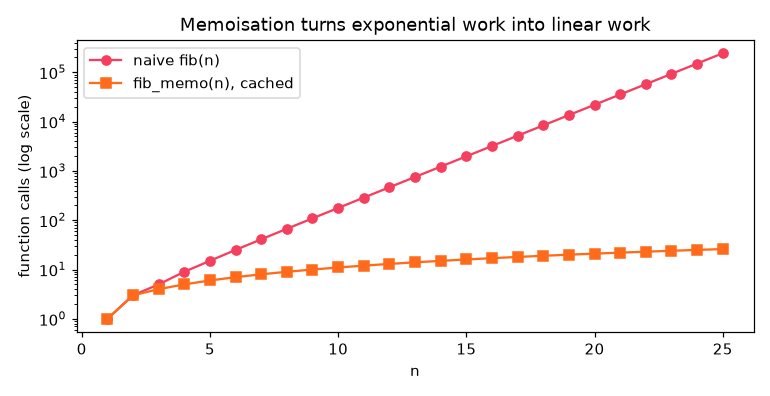

In [3]:
from IPython.display import Image, display
display(Image(filename='session-04_recursion.png'))  # chart saved by the cell above

## Example: `session-04_lambda.py`

In [4]:
"""
Session 4 · Example 2: lambda functions with sorted, map, filter and reduce
---------------------------------------------------------------------------
lambda arguments: expression   -> a small anonymous function of ONE expression
Run:  python session-04_lambda.py
"""
from functools import reduce

square = lambda x: x * x          # works, but a def is clearer for named functions
print("square(7) =", square(7))
add = lambda a, b=10: a + b
print("add(5) =", add(5), "| add(5, 1) =", add(5, 1))

students = [
    {"name": "Ali", "cgpa": 3.1, "city": "Karachi"},
    {"name": "Sana", "cgpa": 3.8, "city": "Lahore"},
    {"name": "Bilal", "cgpa": 2.7, "city": "Karachi"},
    {"name": "Hira", "cgpa": 3.8, "city": "Quetta"},
]

# 1. sorted / max / min with key=lambda: the most common real use
by_cgpa = sorted(students, key=lambda s: s["cgpa"], reverse=True)
print("by cgpa:", [s["name"] for s in by_cgpa])
by_cgpa_then_name = sorted(students, key=lambda s: (-s["cgpa"], s["name"]))
print("tie-break by name:", [s["name"] for s in by_cgpa_then_name])
print("top student:", max(students, key=lambda s: s["cgpa"])["name"])

# 2. map applies a function to every item (returns an iterator)
prices = [1200, 850, 3400]
with_tax = list(map(lambda p: round(p * 1.16), prices))
print("map with tax:", with_tax)

# 3. filter keeps items where the function returns True
karachi = list(filter(lambda s: s["city"] == "Karachi", students))
print("filter Karachi:", [s["name"] for s in karachi])

# 4. reduce folds a sequence into one value
total = reduce(lambda acc, p: acc + p, prices, 0)
longest = reduce(lambda a, b: a if len(a) >= len(b) else b, [s["name"] for s in students])
print("reduce total:", total, "| longest name:", longest)

# Comprehensions often read better than map/filter
print("comprehension:", [round(p * 1.16) for p in prices if p > 1000])

# 5. Lambdas as small callbacks: a dispatch table of operations
ops = {"+": lambda a, b: a + b, "-": lambda a, b: a - b,
       "*": lambda a, b: a * b, "/": lambda a, b: a / b if b else float("nan")}
for sym in ops:
    print(f"  12 {sym} 4 = {ops[sym](12, 4)}")

# 6. A function that RETURNS a lambda (a function factory)
def make_discount(pct):
    return lambda price: round(price * (1 - pct / 100))
eid_sale, clearance = make_discount(20), make_discount(50)
print("Eid sale:", eid_sale(5000), "| clearance:", clearance(5000))

# 7. The late-binding trap in loops
fns = [lambda: i for i in range(3)]
print("late binding:", [f() for f in fns], "-> fix with a default:", [f() for f in [lambda i=i: i for i in range(3)]])

square(7) = 49
add(5) = 15 | add(5, 1) = 6
by cgpa: ['Sana', 'Hira', 'Ali', 'Bilal']
tie-break by name: ['Hira', 'Sana', 'Ali', 'Bilal']
top student: Sana
map with tax: [1392, 986, 3944]
filter Karachi: ['Ali', 'Bilal']
reduce total: 5450 | longest name: Bilal
comprehension: [1392, 3944]
  12 + 4 = 16
  12 - 4 = 8
  12 * 4 = 48
  12 / 4 = 3.0
Eid sale: 4000 | clearance: 2500
late binding: [2, 2, 2] -> fix with a default: [0, 1, 2]


## Example: `session-04_modules_packages.py`

In [5]:
"""
Session 4 · Example 3: using modules and packages
-------------------------------------------------
Needs campus_utils.py and the school/ folder next to this file (both are in code/).
Run:  python session-04_modules_packages.py
"""
import math                                # 1. whole standard-library module
import random as rnd                       # 2. module with an alias
from datetime import date                  # 3. one name from a module
from statistics import mean, median        # 4. several names

print("math.floor(7.8) =", math.floor(7.8), "| rnd seeded pick:", rnd.Random(1).choice(["red", "green", "blue"]))
print("days until 1 Jan 2027 from 26 Oct 2026:", (date(2027, 1, 1) - date(2026, 10, 26)).days)
print("mean/median:", mean([3, 5, 10]), median([3, 5, 10]))

# Our own module (campus_utils.py in the same folder)
import campus_utils
print("\ncampus_utils.grade(77) =", campus_utils.grade(77), "| PASS_MARK =", campus_utils.PASS_MARK)
print("module __name__ when imported:", campus_utils.__name__)
print("public names:", [n for n in dir(campus_utils) if not n.startswith("_")])

from campus_utils import percentage as pct
print("pct(45, 60) =", pct(45, 60))

# Our own package (school/ folder with __init__.py)
import school
from school import report_card
from school.grades import POINTS            # dotted path into a sub-module
print("\nschool version:", school.__version__, "| exported:", school.__all__)
print("grade points:", POINTS)
results = {"Programming Fundamentals": (88, 4), "Statistics": (72, 3),
           "Database Systems": (64, 3), "Communication Skills": (91, 2)}
print(report_card("Hamza Raza", results, scholarship_pct=25))

# Where Python looks for modules: the script folder first, then sys.path entries
import sys
import os
print("\nsys.path has", "many" if len(sys.path) > 3 else "few", "entries; campus_utils.py found in the current folder:", os.path.exists("campus_utils.py"))
print("modules already loaded include math and school:", "math" in sys.modules, "school" in sys.modules)
print("this file's __name__:", __name__)

math.floor(7.8) = 7 | rnd seeded pick: red
days until 1 Jan 2027 from 26 Oct 2026: 67
mean/median: 6 5

campus_utils.grade(77) = B | PASS_MARK = 50
module __name__ when imported: campus_utils
public names: ['GRADE_CUTS', 'PASS_MARK', 'grade', 'percentage']
pct(45, 60) = 75.0

school version: 1.0.0 | exported: ['letter', 'gpa', 'fee_due', 'report_card']
grade points: {'A': 4.0, 'B': 3.0, 'C': 2.0, 'D': 1.0, 'F': 0.0}
Report card: Hamza Raza
  Programming Fundamentals    88  A  (4 cr)
  Statistics                  72  B  (3 cr)
  Database Systems            64  C  (3 cr)
  Communication Skills        91  A  (2 cr)
  GPA 3.25 | fee due Rs 58,500

sys.path has many entries; campus_utils.py found in the current folder: True
modules already loaded include math and school: True True
this file's __name__: __main__


## Example: `session-04_problem_folder_report.py`

In [6]:
"""
Session 4 · Real-life problem: recursive folder-size report
-----------------------------------------------------------
PROBLEM
A lab's shared drive is full. The admin wants a report that
  1. walks a folder and ALL its sub-folders,
  2. prints an indented tree with each folder's total size,
  3. lists the 3 largest files and the size per file type.
Folders contain folders, so the natural solution is RECURSIVE: the size of a
folder = sizes of its files + sizes of its sub-folders (same problem, smaller).

To keep the output identical on every machine, the script first builds a small
demo tree with known file sizes inside a temporary directory.
Run:  python session-04_problem_folder_report.py
"""
import os
import tempfile
from collections import defaultdict

def make_demo_tree(root):
    """Create folders and files of fixed sizes (bytes) for the demo."""
    layout = {
        "lectures/week1/slides.pdf": 2_400_000, "lectures/week1/notes.md": 18_000,
        "lectures/week2/slides.pdf": 3_100_000, "lectures/week2/demo.py": 6_500,
        "datasets/students.csv": 950_000, "datasets/raw/survey_2025.csv": 4_800_000,
        "datasets/raw/images/cat.png": 1_200_000, "datasets/raw/images/dog.png": 1_350_000,
        "submissions/ali.py": 4_200, "submissions/sana.py": 5_100, "README.md": 2_000,
    }
    for rel, size in layout.items():
        path = os.path.join(root, rel)
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, "wb") as f:
            f.write(b"\0" * size)

def human(n):
    """Readable size: 1_234_567 -> '1.2 MB'."""
    for unit in ["B", "KB", "MB", "GB"]:
        if n < 1000:
            return f"{n:.0f} {unit}" if unit == "B" else f"{n:.1f} {unit}"
        n /= 1000
    return f"{n:.1f} TB"

def folder_size(path, depth=0, lines=None, files=None):
    """RECURSIVE: return total bytes under `path`, recording tree lines and files."""
    total = 0
    child_lines = []
    for entry in sorted(os.scandir(path), key=lambda e: (e.is_file(), e.name)):
        if entry.is_dir():
            total += folder_size(entry.path, depth + 1, child_lines, files)   # recursive case
        else:                                                               # base case: a file
            size = entry.stat().st_size
            total += size
            files.append((entry.name, size))
    lines.append(("    " * depth + os.path.basename(path) + "/", total))
    lines.extend(child_lines)
    return total

with tempfile.TemporaryDirectory() as tmp:
    root = os.path.join(tmp, "shared_drive")
    make_demo_tree(root)
    lines, files = [], []
    grand = folder_size(root, 0, lines, files)

print("Folder tree (total size of each folder)")
for text, size in lines:
    print(f"  {text:<28} {human(size):>9}")

print("\nThree largest files")
for name, size in sorted(files, key=lambda f: f[1], reverse=True)[:3]:
    print(f"  {name:<18} {human(size):>9}  ({size / grand:.0%} of the drive)")

by_type = defaultdict(int)
for name, size in files:
    by_type[os.path.splitext(name)[1]] += size
print("\nSize by file type")
for ext, size in sorted(by_type.items(), key=lambda kv: -kv[1]):
    print(f"  {ext:<5} {human(size):>9} {'#' * round(size / grand * 40)}")
print(f"\n{len(files)} files, {human(grand)} in total")

Folder tree (total size of each folder)
  shared_drive/                  13.8 MB
      datasets/                   8.3 MB
          raw/                    7.3 MB
              images/             2.5 MB
      lectures/                   5.5 MB
          week1/                  2.4 MB
          week2/                  3.1 MB
      submissions/                9.3 KB

Three largest files
  survey_2025.csv       4.8 MB  (35% of the drive)
  slides.pdf            3.1 MB  (22% of the drive)
  slides.pdf            2.4 MB  (17% of the drive)

Size by file type
  .csv     5.8 MB #################
  .pdf     5.5 MB ################
  .png     2.5 MB #######
  .md     20.0 KB 
  .py     15.8 KB 

11 files, 13.8 MB in total


## Example: `session-04_project_gradebook.py`

In [7]:
"""
Session 4 · Mini project: a gradebook command-line tool built from a package
---------------------------------------------------------------------------
Files involved (all in code/):
  school/__init__.py, grades.py, fees.py, report.py   <- the package
  gradebook_cli.py                                    <- the CLI module with main()
This script imports the CLI module and calls main() with different argument
lists, exactly as if you had typed the commands in a terminal.
Run:  python session-04_project_gradebook.py
"""
import contextlib
import sys

import gradebook_cli

commands = [
    ["grade", "49", "70", "85", "93"],
    ["report", "Hira", "88:4", "72:3", "64:3", "91:2"],
    ["fee", "15"],
    ["fee", "15", "--scholarship", "50", "--late"],
]
for argv in commands:
    print("$ python gradebook_cli.py", " ".join(argv))
    gradebook_cli.main(argv)
    print()

# argparse also generates help text and error messages for free
print("$ python gradebook_cli.py fee --help")
try:
    gradebook_cli.main(["fee", "--help"])
except SystemExit:
    pass                      # argparse exits after printing help
print("\n$ python gradebook_cli.py fee lots")
try:
    with contextlib.redirect_stderr(sys.stdout):   # show argparse's error message in normal output
        gradebook_cli.main(["fee", "lots"])
except SystemExit as e:
    print("(exit code", e.code, ")")

$ python gradebook_cli.py grade 49 70 85 93
 49 -> F
 70 -> B
 85 -> A
 93 -> A

$ python gradebook_cli.py report Hira 88:4 72:3 64:3 91:2
Hira: 4 courses, 12 credits, GPA 3.25

$ python gradebook_cli.py fee 15
Fee for 15 credits: Rs 97,500

$ python gradebook_cli.py fee 15 --scholarship 50 --late
Fee for 15 credits: Rs 50,750

$ python gradebook_cli.py fee --help
usage: gradebook fee [-h] [--scholarship SCHOLARSHIP] [--late] credits

positional arguments:
  credits

options:
  -h, --help            show this help message and exit
  --scholarship SCHOLARSHIP
  --late

$ python gradebook_cli.py fee lots
usage: gradebook fee [-h] [--scholarship SCHOLARSHIP] [--late] credits
gradebook fee: error: argument credits: invalid int value: 'lots'
(exit code 2 )
